# Intelligent Parking Space Monitoring System
## Jupyter Notebook: Data Visualization and Experimental Analysis

**Project hardware:** Arduino Uno R3 + three Parallax PING))) ultrasonic distance sensors + three red and three green LEDs.

**Pipeline:** ultrasonic distance acquisition → Arduino occupancy classification → CSV serial records → Python/Pandas analysis → Matplotlib visualizations.

This notebook is designed for the repository's `data/parking_data.csv` schema. It analyses three parking slots and treats `UNKNOWN` readings separately from `VACANT` readings.

> **Academic integrity and data provenance:** If the repository has no collected CSV yet, this notebook generates a small deterministic synthetic dataset solely to demonstrate the workflow. Synthetic data is explicitly labelled in outputs and must never be reported as Tinkercad or physical experimental measurement. Replace it by running the circuit and importing/acquiring your own records.

## 1. Learning objectives

By running this notebook, you will:

1. Load and validate the parking-system CSV measurements.
2. Summarize occupied, vacant and unknown states.
3. Compare utilization across the three slots.
4. Visualize ultrasonic distance measurements over time.
5. Investigate measurement spread and repeatability.
6. Export figures and summary tables for the laboratory report.

### Expected CSV columns

The Python receiver writes `received_at_utc`, `arduino_timestamp_ms`, three distance/status pairs, and `occupied_count`, `vacant_count`, `unknown_count`. The serial protocol and schema are documented in `docs/DATA_FORMAT.md`.

## 2. Environment setup

From the repository root, create and activate a virtual environment, then install the project with its notebook extra:

```bash
python3 -m venv venv
source venv/bin/activate        # macOS / Linux
python -m pip install --upgrade pip
python -m pip install -e "./python[notebook]"
```

Start this notebook from the repository root with:

```bash
jupyter lab notebooks/parking_data_visualization.ipynb
```

In [2]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Resolve the repository root whether Jupyter starts from the root or notebooks/.
CURRENT_DIR = Path.cwd().resolve()
if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
elif (CURRENT_DIR / "firmware").exists() and (CURRENT_DIR / "python").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "firmware").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

DATA_FILE = PROJECT_ROOT / "data" / "parking_data.csv"
REPORT_DIR = PROJECT_ROOT / "reports" / "notebook"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Change this label before exporting plots for your report.
# Examples: "Tinkercad simulation capture" or "Physical Arduino experiment".
DATA_PROVENANCE = "Collected CSV — provenance not yet specified"

print(f"Project root: {PROJECT_ROOT}")
print(f"Input CSV:    {DATA_FILE}")
print(f"Output dir:   {REPORT_DIR}")

Project root: /Users/subhankarbiswas/MDE-CO-06_Data-Acquisition-Technologies-and-Sensor-Networks_Group_Project
Input CSV:    /Users/subhankarbiswas/MDE-CO-06_Data-Acquisition-Technologies-and-Sensor-Networks_Group_Project/data/parking_data.csv
Output dir:   /Users/subhankarbiswas/MDE-CO-06_Data-Acquisition-Technologies-and-Sensor-Networks_Group_Project/reports/notebook


## 3. Load the dataset

The primary input is `data/parking_data.csv`, generated by either:

- the live Python receiver connected to a physical Arduino (`parking_monitor.monitor`), or
- the Tinkercad Serial Monitor text importer (`parking_monitor.import_capture`).

For a first preview only, the cell below creates synthetic demonstration data when the real CSV is absent. The source label is carried into every plot title and the summary. When a real CSV is available, it takes precedence automatically.

In [3]:
USE_SYNTHETIC_DEMO_IF_CSV_MISSING = True  # Set False to require actual collected data.

REQUIRED_COLUMNS = [
    "received_at_utc",
    "arduino_timestamp_ms",
    "slot1_distance_cm", "slot1_status",
    "slot2_distance_cm", "slot2_status",
    "slot3_distance_cm", "slot3_status",
    "occupied_count", "vacant_count", "unknown_count",
]


def make_synthetic_demo_data(n_records: int = 133) -> pd.DataFrame:
    """Create deterministic example rows for notebook demonstration only."""
    base_time = pd.Timestamp("2026-01-01T09:00:00Z")
    patterns = [
        ("VACANT", "VACANT", "VACANT"),
        ("OCCUPIED", "VACANT", "VACANT"),
        ("OCCUPIED", "VACANT", "OCCUPIED"),
        ("OCCUPIED", "UNKNOWN", "OCCUPIED"),
        ("VACANT", "OCCUPIED", "OCCUPIED"),
        ("VACANT", "VACANT", "OCCUPIED"),
        ("UNKNOWN", "VACANT", "VACANT"),
        ("OCCUPIED", "OCCUPIED", "OCCUPIED"),
    ]
    rows = []
    for i in range(n_records):
        statuses = patterns[i % len(patterns)]
        row = {
            "received_at_utc": (base_time + pd.Timedelta(seconds=10 * i)).isoformat(),
            "arduino_timestamp_ms": i * 10000,
        }
        for slot, status in enumerate(statuses, start=1):
            if status == "OCCUPIED":
                # Illustrative short distances with slight deterministic variation.
                distance = 11.5 + slot * 1.3 + (i % 5) * 0.35
            elif status == "VACANT":
                distance = 48.0 + slot * 4.0 + (i % 7) * 0.6
            else:
                distance = -1.0  # No echo / unresolved reading sentinel.
            row[f"slot{slot}_distance_cm"] = round(distance, 2)
            row[f"slot{slot}_status"] = status
        row["occupied_count"] = sum(s == "OCCUPIED" for s in statuses)
        row["vacant_count"] = sum(s == "VACANT" for s in statuses)
        row["unknown_count"] = sum(s == "UNKNOWN" for s in statuses)
        rows.append(row)
    return pd.DataFrame(rows)


if DATA_FILE.is_file():
    df_raw = pd.read_csv(DATA_FILE)
    DATA_SOURCE_LABEL = DATA_PROVENANCE
    print(f"Loaded collected dataset: {len(df_raw):,} records")
elif USE_SYNTHETIC_DEMO_IF_CSV_MISSING:
    df_raw = make_synthetic_demo_data()
    DATA_SOURCE_LABEL = "SYNTHETIC DEMONSTRATION DATA — NOT EXPERIMENTAL RESULTS"
    print("WARNING: data/parking_data.csv was not found.")
    print("Using synthetic demonstration records only to preview the notebook.")
else:
    raise FileNotFoundError(
        f"No collected dataset found at {DATA_FILE}. Run the Arduino/Python "
        "acquisition workflow or import a Tinkercad capture first."
    )

missing_columns = sorted(set(REQUIRED_COLUMNS) - set(df_raw.columns))
if missing_columns:
    raise ValueError(f"CSV is missing required columns: {missing_columns}")

print(f"Data source: {DATA_SOURCE_LABEL}")
display(df_raw.head())

Loaded collected dataset: 133 records
Data source: Collected CSV — provenance not yet specified


,received_at_utc,arduino_timestamp_ms,slot1_distance_cm,slot1_status,slot2_distance_cm,slot2_status,slot3_distance_cm,slot3_status,occupied_count,vacant_count,unknown_count
0,2026-11-08T16:29:23.877+00:00,488,111.32,VACANT,112.88,VACANT,113.09,VACANT,0,3,0
1,2026-11-08T16:29:23.878+00:00,934,113.07,VACANT,112.88,VACANT,112.95,VACANT,0,3,0
2,2026-11-08T16:29:23.878+00:00,1381,113.07,VACANT,112.92,VACANT,112.88,VACANT,0,3,0
3,2026-11-08T16:29:23.878+00:00,1827,113.07,VACANT,113.07,VACANT,113.07,VACANT,0,3,0
4,2026-11-08T16:29:23.878+00:00,2248,8.97,OCCUPIED,113.04,VACANT,125.71,VACANT,1,2,0


## 4. Clean and validate the measurements

- Parse received timestamps as UTC.
- Convert numeric fields to numeric types.
- Normalize status text.
- Keep only the defined statuses: `OCCUPIED`, `VACANT`, `UNKNOWN`.
- Recalculate status counts and compare them with the counts transmitted by Arduino.
- Retain `-1` as the no-echo sentinel, but exclude it from distance statistics and plots.

The notebook does not silently relabel a missing/no-echo measurement as vacant.

In [4]:
STATUS_VALUES = {"OCCUPIED", "VACANT", "UNKNOWN"}
df = df_raw.copy()

df["received_at_utc"] = pd.to_datetime(
    df["received_at_utc"], errors="coerce", utc=True
)
for slot in range(1, 4):
    distance_col = f"slot{slot}_distance_cm"
    status_col = f"slot{slot}_status"
    df[distance_col] = pd.to_numeric(df[distance_col], errors="coerce")
    df[status_col] = df[status_col].astype("string").str.strip().str.upper()

for col in ["arduino_timestamp_ms", "occupied_count", "vacant_count", "unknown_count"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

before_rows = len(df)
df = df.dropna(subset=["received_at_utc", "arduino_timestamp_ms"]).copy()
for slot in range(1, 4):
    df = df[df[f"slot{slot}_status"].isin(STATUS_VALUES)]

df = df.sort_values("received_at_utc").reset_index(drop=True)
if df.empty:
    raise ValueError("No valid parking records remain after data validation.")

# Recalculate counts from the three slot status columns.
for status in ["OCCUPIED", "VACANT", "UNKNOWN"]:
    df[f"recalculated_{status.lower()}_count"] = sum(
        df[f"slot{slot}_status"].eq(status).astype(int) for slot in range(1, 4)
    )

counts_match = (
    df["occupied_count"].eq(df["recalculated_occupied_count"])
    & df["vacant_count"].eq(df["recalculated_vacant_count"])
    & df["unknown_count"].eq(df["recalculated_unknown_count"])
)

print(f"Rows read: {before_rows:,}")
print(f"Rows retained after validation: {len(df):,}")
print(f"Rows dropped: {before_rows - len(df):,}")
print(f"Rows with summary counts consistent with slot statuses: {counts_match.sum():,}/{len(df):,}")
if not counts_match.all():
    warnings.warn("Some stored summary counts do not match the three slot status fields.")

display(df.head())

Rows read: 133
Rows retained after validation: 133
Rows dropped: 0
Rows with summary counts consistent with slot statuses: 133/133


,received_at_utc,arduino_timestamp_ms,slot1_distance_cm,slot1_status,slot2_distance_cm,slot2_status,slot3_distance_cm,slot3_status,occupied_count,vacant_count,unknown_count,recalculated_occupied_count,recalculated_vacant_count,recalculated_unknown_count
0,2026-11-08 16:29:23.877+00:00,488,111.32,VACANT,112.88,VACANT,113.09,VACANT,0,3,0,0,3,0
1,2026-11-08 16:29:23.878+00:00,934,113.07,VACANT,112.88,VACANT,112.95,VACANT,0,3,0,0,3,0
2,2026-11-08 16:29:23.878+00:00,1381,113.07,VACANT,112.92,VACANT,112.88,VACANT,0,3,0,0,3,0
3,2026-11-08 16:29:23.878+00:00,1827,113.07,VACANT,113.07,VACANT,113.07,VACANT,0,3,0,0,3,0
4,2026-11-08 16:29:23.878+00:00,2248,8.97,OCCUPIED,113.04,VACANT,125.71,VACANT,1,2,0,1,2,0


## 5. Dataset overview and key performance indicators

The utilization denominator excludes `UNKNOWN` slots. This avoids incorrectly treating a sensor timeout as an empty parking bay.

In [5]:
record_count = len(df)
start_time = df["received_at_utc"].min()
end_time = df["received_at_utc"].max()
duration_minutes = (end_time - start_time).total_seconds() / 60 if record_count > 1 else 0.0

known_slots_per_record = df["occupied_count"] + df["vacant_count"]
total_known_observations = known_slots_per_record.sum()
total_occupied_observations = df["occupied_count"].sum()
total_vacant_observations = df["vacant_count"].sum()

mean_utilization = (
    total_occupied_observations / total_known_observations * 100
    if total_known_observations else np.nan
)

kpi_table = pd.DataFrame({
    "Metric": [
        "Valid records", "Observation window (minutes)",
        "Mean occupied slots per scan", "Mean vacant slots per scan",
        "Mean unknown slots per scan", "Overall utilization among known slots (%)",
        "Summary-count consistency (%)",
    ],
    "Value": [
        record_count, round(duration_minutes, 2),
        round(df["occupied_count"].mean(), 3),
        round(df["vacant_count"].mean(), 3),
        round(df["unknown_count"].mean(), 3),
        round(mean_utilization, 2) if pd.notna(mean_utilization) else np.nan,
        round(counts_match.mean() * 100, 2),
    ],
})
display(kpi_table)

,Metric,Value
0,Valid records,133.000
1,Observation window (minutes),0.000
2,Mean occupied slots per scan,0.752
3,Mean vacant slots per scan,1.805
4,Mean unknown slots per scan,0.444
5,Overall utilization among known slots (%),29.410
6,Summary-count consistency (%),100.000


## 6. Slot-wise occupancy and status composition

For each parking slot, the occupied percentage is calculated only across known (`OCCUPIED` or `VACANT`) records. Unknown readings are shown separately.

,Slot,Occupied readings,Vacant readings,Unknown readings,Known readings,Occupied among known (%),Unknown (%)
0,Slot 1,31,84,18,115,26.96,13.53
1,Slot 2,17,85,31,102,16.67,23.31
2,Slot 3,52,71,10,123,42.28,7.52


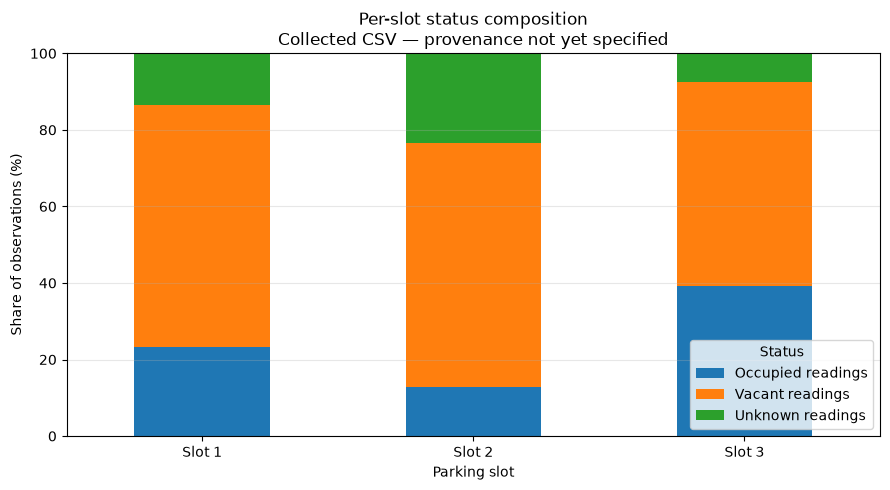

In [6]:
slot_rows = []
for slot in range(1, 4):
    status = df[f"slot{slot}_status"]
    known = status.isin(["OCCUPIED", "VACANT"])
    known_n = int(known.sum())
    occupied_n = int(status.eq("OCCUPIED").sum())
    vacant_n = int(status.eq("VACANT").sum())
    unknown_n = int(status.eq("UNKNOWN").sum())
    slot_rows.append({
        "Slot": f"Slot {slot}",
        "Occupied readings": occupied_n,
        "Vacant readings": vacant_n,
        "Unknown readings": unknown_n,
        "Known readings": known_n,
        "Occupied among known (%)": occupied_n / known_n * 100 if known_n else np.nan,
        "Unknown (%)": unknown_n / len(df) * 100,
    })
slot_summary = pd.DataFrame(slot_rows)
display(slot_summary.round(2))

status_share = slot_summary.set_index("Slot")[
    ["Occupied readings", "Vacant readings", "Unknown readings"]
].div(len(df)).mul(100)
ax = status_share.plot(kind="bar", stacked=True, figsize=(9, 5))
ax.set_title(f"Per-slot status composition\n{DATA_SOURCE_LABEL}")
ax.set_xlabel("Parking slot")
ax.set_ylabel("Share of observations (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Status")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(REPORT_DIR / "slot_status_composition.png", dpi=180, bbox_inches="tight")
plt.show()

## 7. Parking occupancy over time

This graph tracks the number of occupied, vacant and unknown slots for every scan. The optional rolling mean smooths short-term fluctuations for interpretation; it does not modify the source data.

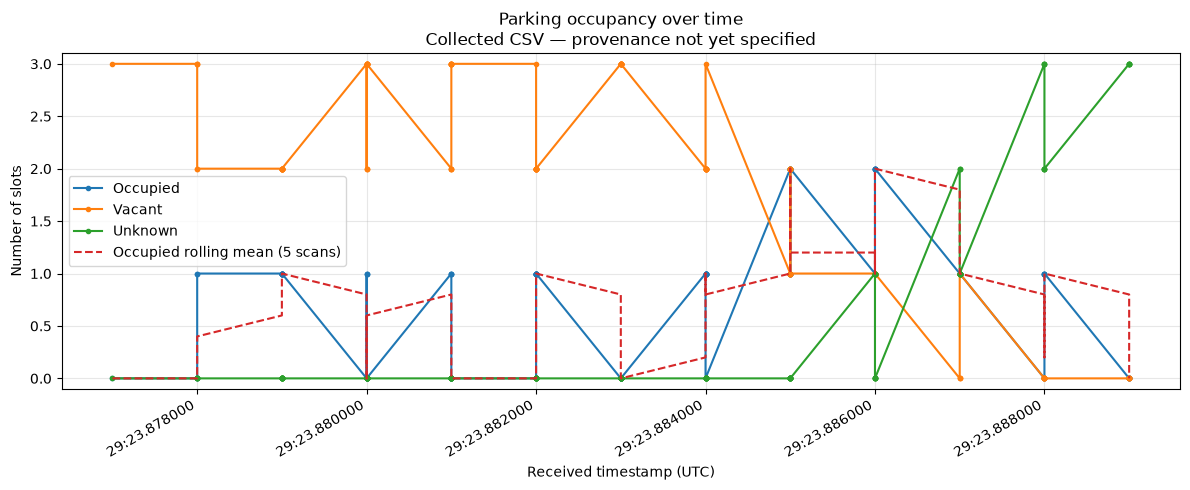

In [7]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df["received_at_utc"], df["occupied_count"], marker=".", label="Occupied")
ax.plot(df["received_at_utc"], df["vacant_count"], marker=".", label="Vacant")
ax.plot(df["received_at_utc"], df["unknown_count"], marker=".", label="Unknown")

rolling_window = min(5, len(df))
if rolling_window >= 2:
    rolling_occupied = df["occupied_count"].rolling(rolling_window, min_periods=1).mean()
    ax.plot(df["received_at_utc"], rolling_occupied, linestyle="--", label=f"Occupied rolling mean ({rolling_window} scans)")

ax.set_title(f"Parking occupancy over time\n{DATA_SOURCE_LABEL}")
ax.set_xlabel("Received timestamp (UTC)")
ax.set_ylabel("Number of slots")
ax.set_ylim(-0.1, 3.1)
ax.grid(True, alpha=0.3)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(REPORT_DIR / "occupancy_over_time.png", dpi=180, bbox_inches="tight")
plt.show()

## 8. Ultrasonic distance measurements over time

The Arduino reports `-1` when no echo is received. Those values are omitted from distance traces. The two horizontal reference lines are the firmware's initial classification thresholds (25 cm occupied and 30 cm vacant); they must be calibrated for the model and sensor placement.

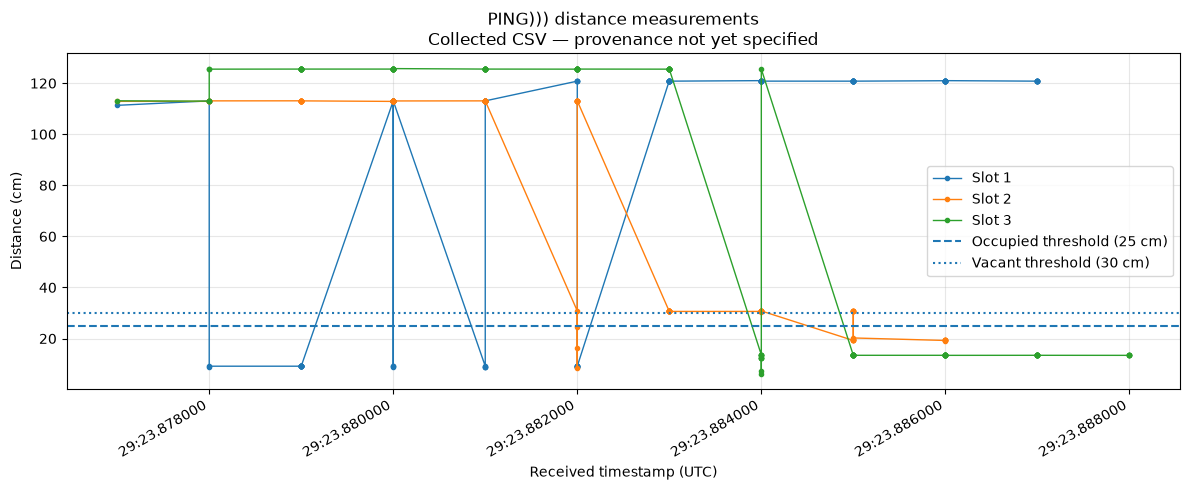

In [8]:
fig, ax = plt.subplots(figsize=(12, 5))
for slot in range(1, 4):
    distance_col = f"slot{slot}_distance_cm"
    valid = df[distance_col].notna() & (df[distance_col] >= 0)
    ax.plot(
        df.loc[valid, "received_at_utc"],
        df.loc[valid, distance_col],
        marker=".",
        linewidth=1,
        label=f"Slot {slot}",
    )

ax.axhline(25, linestyle="--", label="Occupied threshold (25 cm)")
ax.axhline(30, linestyle=":", label="Vacant threshold (30 cm)")
ax.set_title(f"PING))) distance measurements\n{DATA_SOURCE_LABEL}")
ax.set_xlabel("Received timestamp (UTC)")
ax.set_ylabel("Distance (cm)")
ax.grid(True, alpha=0.3)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(REPORT_DIR / "distance_measurements.png", dpi=180, bbox_inches="tight")
plt.show()

## 9. Measurement distribution and repeatability indicators

The next table reports mean, standard deviation, minimum, maximum and sample count for valid distance readings. These statistics describe the recorded values; they are not an accuracy claim. To calculate measurement error, compare readings against a measured reference distance.

,Slot,Valid readings (n),Mean (cm),Std. dev. (cm),Minimum (cm),Maximum (cm)
0,Slot 1,115,89.237,48.981,8.97,120.99
1,Slot 2,102,71.502,43.613,8.42,113.09
2,Slot 3,123,77.608,55.468,6.26,125.71


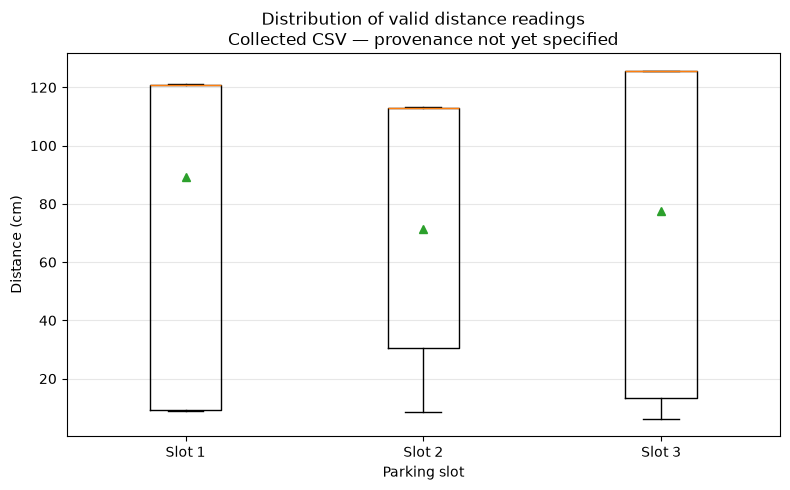

In [9]:
distance_rows = []

for slot in range(1, 4):
    col = f"slot{slot}_distance_cm"

    values = pd.to_numeric(df[col], errors="coerce")
    valid_values = values[values >= 0].dropna()

    distance_rows.append({
        "Slot": f"Slot {slot}",
        "Valid readings (n)": int(valid_values.size),
        "Mean (cm)": valid_values.mean() if len(valid_values) else np.nan,
        "Std. dev. (cm)": (
            valid_values.std(ddof=1)
            if len(valid_values) > 1 else np.nan
        ),
        "Minimum (cm)": valid_values.min() if len(valid_values) else np.nan,
        "Maximum (cm)": valid_values.max() if len(valid_values) else np.nan,
    })

distance_summary = pd.DataFrame(distance_rows)

display(distance_summary.round(3))


# Prepare data for boxplot
box_data = []
box_labels = []

for slot in range(1, 4):

    values = pd.to_numeric(
        df[f"slot{slot}_distance_cm"],
        errors="coerce"
    )

    values = values[values >= 0].dropna().to_numpy()

    if len(values):
        box_data.append(values)
        box_labels.append(f"Slot {slot}")


# Generate boxplot
if box_data:

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.boxplot(
        box_data,
        tick_labels=box_labels,
        showmeans=True
    )

    ax.set_title(
        f"Distribution of valid distance readings\n{DATA_SOURCE_LABEL}"
    )

    ax.set_xlabel("Parking slot")
    ax.set_ylabel("Distance (cm)")

    ax.grid(axis="y", alpha=0.3)

    fig.tight_layout()

    fig.savefig(
        REPORT_DIR / "distance_distribution.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()

else:
    print(
        "No valid distance readings available "
        "for a distribution plot."
    )


## 10. Parking-state heatmap

The heatmap maps `OCCUPIED` to 1, `VACANT` to 0 and `UNKNOWN` to a missing value. It offers a compact view of how each slot changes over the observation period.

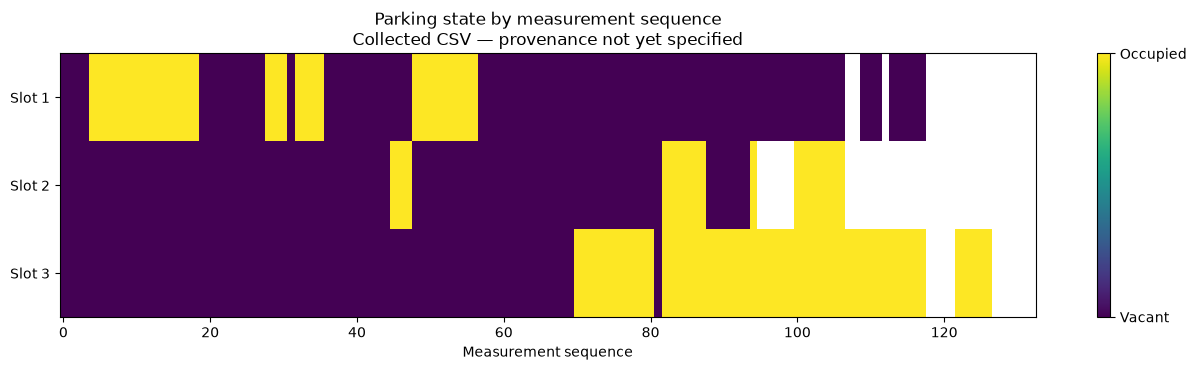

In [10]:
state_matrix = np.vstack([
    df[f"slot{slot}_status"].map({"VACANT": 0, "OCCUPIED": 1, "UNKNOWN": np.nan}).to_numpy(dtype=float)
    for slot in range(1, 4)
])

fig, ax = plt.subplots(figsize=(13, 3.8))
image = ax.imshow(state_matrix, aspect="auto", interpolation="nearest", vmin=0, vmax=1)
ax.set_yticks([0, 1, 2], labels=["Slot 1", "Slot 2", "Slot 3"])
ax.set_xlabel("Measurement sequence")
ax.set_title(f"Parking state by measurement sequence\n{DATA_SOURCE_LABEL}")
colorbar = fig.colorbar(image, ax=ax, ticks=[0, 1])
colorbar.ax.set_yticklabels(["Vacant", "Occupied"])
fig.tight_layout()
fig.savefig(REPORT_DIR / "parking_state_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()

## 11. Unknown readings and acquisition quality

`UNKNOWN` may indicate no echo, an unresolved first reading in the hysteresis band, poor sensor alignment, target geometry, wiring issues or another acquisition problem. Review these readings instead of counting them as vacant spaces.

In [11]:
quality_rows = []
for slot in range(1, 4):
    status = df[f"slot{slot}_status"]
    unknown_count = int(status.eq("UNKNOWN").sum())
    no_echo_count = int(pd.to_numeric(df[f"slot{slot}_distance_cm"], errors="coerce").eq(-1).sum())
    quality_rows.append({
        "Slot": f"Slot {slot}",
        "Unknown status count": unknown_count,
        "Unknown status (%)": unknown_count / len(df) * 100,
        "No-echo sentinel count (-1)": no_echo_count,
    })
quality_summary = pd.DataFrame(quality_rows)
display(quality_summary.round(2))

,Slot,Unknown status count,Unknown status (%),No-echo sentinel count (-1)
0,Slot 1,18,13.53,18
1,Slot 2,31,23.31,31
2,Slot 3,10,7.52,10


## 12. Export report tables and a text summary

The following outputs are saved under `reports/notebook/`:

- `slot_summary.csv`
- `distance_summary.csv`
- `data_quality_summary.csv`
- `notebook_analysis_summary.txt`
- PNG plots created in the previous sections.

In [12]:
slot_summary.to_csv(REPORT_DIR / "slot_summary.csv", index=False)
distance_summary.to_csv(REPORT_DIR / "distance_summary.csv", index=False)
quality_summary.to_csv(REPORT_DIR / "data_quality_summary.csv", index=False)

summary_lines = [
    "INTELLIGENT PARKING SPACE MONITORING — NOTEBOOK ANALYSIS",
    "=" * 64,
    f"Data source: {DATA_SOURCE_LABEL}",
    f"Records analysed: {record_count}",
    f"Observation start (UTC): {start_time}",
    f"Observation end (UTC): {end_time}",
    f"Observation window (minutes): {duration_minutes:.2f}",
    f"Overall utilization among known slot observations (%): {mean_utilization:.2f}" if pd.notna(mean_utilization) else "Overall utilization: n/a",
    f"Rows with consistent summary counts: {int(counts_match.sum())}/{len(df)}",
    "",
    "SLOT SUMMARY",
    slot_summary.round(2).to_string(index=False),
    "",
    "DISTANCE SUMMARY",
    distance_summary.round(3).to_string(index=False),
    "",
    "DATA QUALITY SUMMARY",
    quality_summary.round(2).to_string(index=False),
]
summary_text = "\n".join(summary_lines)
(REPORT_DIR / "notebook_analysis_summary.txt").write_text(summary_text, encoding="utf-8")
print(summary_text)
print(f"\nNotebook outputs saved to: {REPORT_DIR}")

INTELLIGENT PARKING SPACE MONITORING — NOTEBOOK ANALYSIS
Data source: Collected CSV — provenance not yet specified
Records analysed: 133
Observation start (UTC): 2026-11-08 16:29:23.877000+00:00
Observation end (UTC): 2026-11-08 16:29:23.889000+00:00
Observation window (minutes): 0.00
Overall utilization among known slot observations (%): 29.41
Rows with consistent summary counts: 133/133

SLOT SUMMARY
  Slot  Occupied readings  Vacant readings  Unknown readings  Known readings  Occupied among known (%)  Unknown (%)
Slot 1                 31               84                18             115                     26.96        13.53
Slot 2                 17               85                31             102                     16.67        23.31
Slot 3                 52               71                10             123                     42.28         7.52

DISTANCE SUMMARY
  Slot  Valid readings (n)  Mean (cm)  Std. dev. (cm)  Minimum (cm)  Maximum (cm)
Slot 1                 115    

## 13. Interpretation questions for the laboratory report

Answer these questions using your **collected** dataset, not the synthetic preview:

1. Which parking slot had the highest occupied percentage among known readings? How many readings were available for that calculation?
2. What was the average number of occupied and vacant spaces per scan?
3. Did the three sensors produce similar distance variation when targets remained stationary?
4. How frequently did each slot report `UNKNOWN`? What physical or simulation conditions may explain those records?
5. Did state changes occur close to the 25 cm / 30 cm thresholds? Did hysteresis reduce rapid classification changes?
6. What is the measured mean absolute error against a known reference distance? Include the reference measurement procedure and sample size.
7. Are there enough records and sufficiently varied occupancy states to support your conclusions?

### Reporting reminder

Do not report the synthetic demonstration results as experimental findings. State whether your dataset came from Tinkercad simulation or physical hardware. Include the number of records, observation window, threshold settings and any data exclusions.

## 14. Additional visualisations

The following supplementary analyses extend the original notebook without replacing its existing sections, tables, plots, data-cleaning logic or interpretation questions. They reuse the validated `df` dataset and preserve the `UNKNOWN` and no-echo handling established above.

All additional figures are saved in `reports/notebook/`. If the dataset is the synthetic preview, the source label remains visible in the figure titles; do not use those results as experimental findings.

### 14.1 Overall parking-state composition

This donut chart summarizes all slot observations. `UNKNOWN` observations are kept as a separate category rather than being counted as vacant.

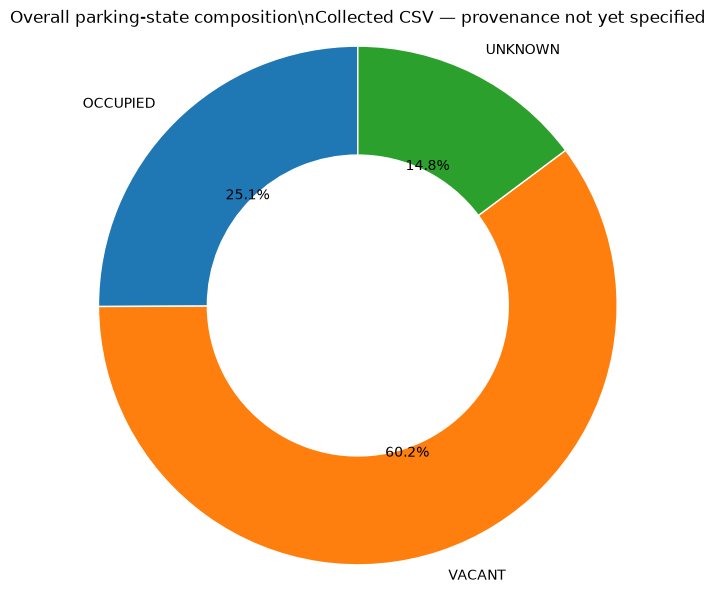

In [13]:
# Aggregate all three slots while retaining UNKNOWN as its own category.
all_status = pd.concat(
    [df[f"slot{slot}_status"] for slot in range(1, 4)],
    ignore_index=True
)
overall_status_counts = (
    all_status.value_counts()
    .reindex(["OCCUPIED", "VACANT", "UNKNOWN"], fill_value=0)
)

fig, ax = plt.subplots(figsize=(7, 6))
if overall_status_counts.sum() > 0:
    ax.pie(
        overall_status_counts,
        labels=overall_status_counts.index,
        autopct="%1.1f%%",
        startangle=90,
        wedgeprops={"width": 0.42, "edgecolor": "white"}
    )
    ax.set_title(f"Overall parking-state composition\\n{DATA_SOURCE_LABEL}")
    ax.axis("equal")
    fig.tight_layout()
    fig.savefig(REPORT_DIR / "overall_state_donut.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("No slot-state observations available for the donut chart.")

### 14.2 Distance histograms by sensor

Histograms show the distribution and possible clustering of valid distance readings for each sensor. The `-1` no-echo sentinel is excluded.

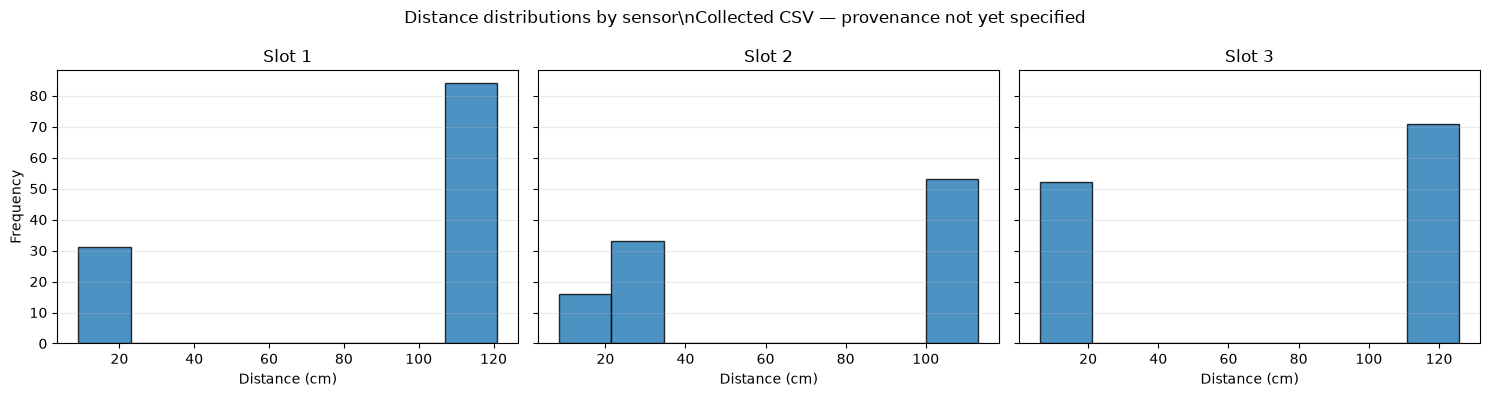

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for slot, ax in enumerate(axes, start=1):
    values = pd.to_numeric(df[f"slot{slot}_distance_cm"], errors="coerce")
    values = values[values >= 0].dropna()
    if len(values):
        ax.hist(values, bins="auto", edgecolor="black", alpha=0.8)
    else:
        ax.text(0.5, 0.5, "No valid readings", ha="center", va="center", transform=ax.transAxes)
    ax.set_title(f"Slot {slot}")
    ax.set_xlabel("Distance (cm)")
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Frequency")
fig.suptitle(f"Distance distributions by sensor\\n{DATA_SOURCE_LABEL}")
fig.tight_layout()
fig.savefig(REPORT_DIR / "distance_histograms.png", dpi=180, bbox_inches="tight")
plt.show()

### 14.3 Violin plots of distance readings

Violin plots provide a view of distribution shape in addition to the summary statistics and boxplot already shown in Section 9.

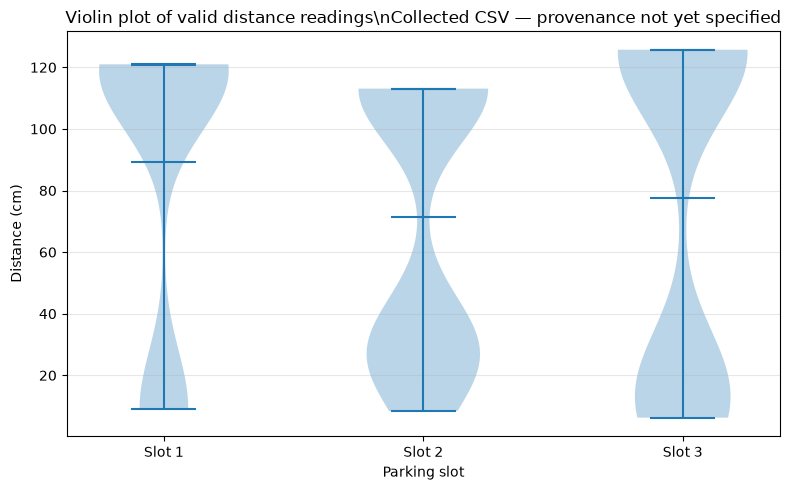

In [15]:
violin_data, violin_labels = [], []
for slot in range(1, 4):
    values = pd.to_numeric(df[f"slot{slot}_distance_cm"], errors="coerce")
    values = values[values >= 0].dropna().to_numpy()
    if len(values):
        violin_data.append(values)
        violin_labels.append(f"Slot {slot}")

if violin_data:
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.violinplot(violin_data, showmeans=True, showmedians=True, showextrema=True)
    ax.set_xticks(range(1, len(violin_labels) + 1), labels=violin_labels)
    ax.set_title(f"Violin plot of valid distance readings\\n{DATA_SOURCE_LABEL}")
    ax.set_xlabel("Parking slot")
    ax.set_ylabel("Distance (cm)")
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    fig.savefig(REPORT_DIR / "distance_violin_plots.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("No valid distance readings available for violin plots.")

### 14.4 Moving-average distance trends

A rolling mean helps reveal slower changes in measured distance. It is a derived visualization only; raw measurements remain unchanged. The window is expressed in scans, not minutes.

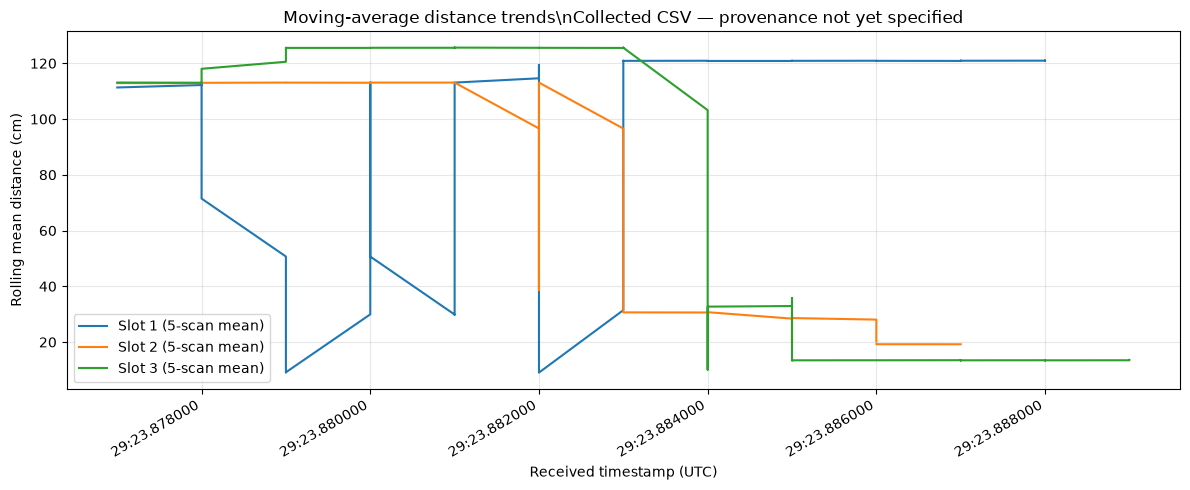

In [16]:
distance_window = min(5, len(df))
fig, ax = plt.subplots(figsize=(12, 5))
for slot in range(1, 4):
    col = f"slot{slot}_distance_cm"
    values = pd.to_numeric(df[col], errors="coerce").where(df[col] >= 0)
    rolling = values.rolling(distance_window, min_periods=1).mean()
    ax.plot(df["received_at_utc"], rolling, label=f"Slot {slot} ({distance_window}-scan mean)")
ax.set_title(f"Moving-average distance trends\\n{DATA_SOURCE_LABEL}")
ax.set_xlabel("Received timestamp (UTC)")
ax.set_ylabel("Rolling mean distance (cm)")
ax.grid(True, alpha=0.3)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(REPORT_DIR / "distance_moving_average.png", dpi=180, bbox_inches="tight")
plt.show()

### 14.5 Correlation between sensor distances

The correlation matrix uses valid non-negative distance readings. Pairwise correlation is calculated only where sufficient overlapping measurements exist; correlation does not by itself establish sensor agreement or accuracy.

,Slot 1,Slot 2,Slot 3
Slot 1,1.000,-0.678,-0.517
Slot 2,-0.678,1.000,0.693
Slot 3,-0.517,0.693,1.000


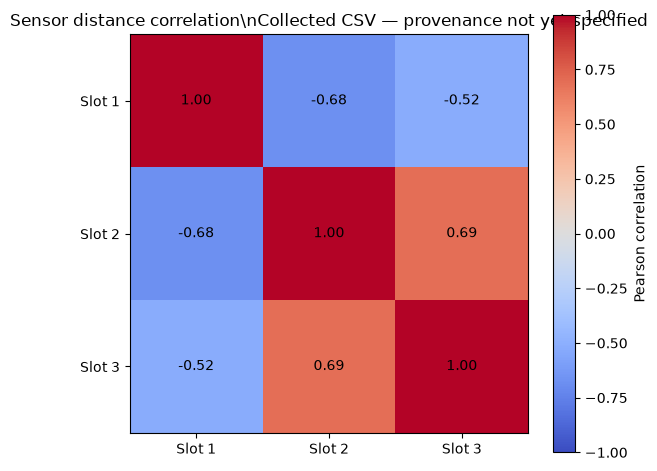

In [17]:
distance_frame = pd.DataFrame({
    f"Slot {slot}": pd.to_numeric(df[f"slot{slot}_distance_cm"], errors="coerce").where(
        pd.to_numeric(df[f"slot{slot}_distance_cm"], errors="coerce") >= 0
    )
    for slot in range(1, 4)
})
correlation = distance_frame.corr(min_periods=2)
display(correlation.round(3))

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(correlation.to_numpy(dtype=float), vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(3), labels=correlation.columns)
ax.set_yticks(range(3), labels=correlation.index)
for row in range(3):
    for col in range(3):
        value = correlation.iloc[row, col]
        ax.text(col, row, f"{value:.2f}" if pd.notna(value) else "n/a",
                ha="center", va="center")
ax.set_title(f"Sensor distance correlation\\n{DATA_SOURCE_LABEL}")
fig.colorbar(image, ax=ax, label="Pearson correlation")
fig.tight_layout()
fig.savefig(REPORT_DIR / "sensor_distance_correlation.png", dpi=180, bbox_inches="tight")
plt.show()

### 14.6 Mean distance with standard-deviation error bars

This chart compares the mean valid distance and one standard deviation for each slot. Error bars describe observed spread; they are not confidence intervals.

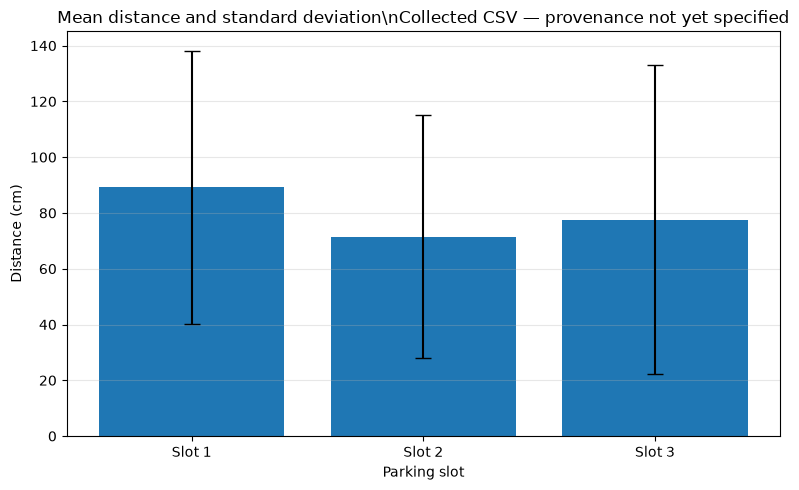

In [18]:
means = distance_summary["Mean (cm)"].to_numpy(dtype=float)
stds = distance_summary["Std. dev. (cm)"].to_numpy(dtype=float)
labels = distance_summary["Slot"].tolist()
x = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x, means, yerr=stds, capsize=6)
ax.set_xticks(x, labels=labels)
ax.set_title(f"Mean distance and standard deviation\\n{DATA_SOURCE_LABEL}")
ax.set_xlabel("Parking slot")
ax.set_ylabel("Distance (cm)")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(REPORT_DIR / "distance_mean_std_errorbars.png", dpi=180, bbox_inches="tight")
plt.show()

### 14.7 Parking-state transition timeline

Each point marks a change from the previous scan for that slot. This highlights when classifications change, but does not prove whether a transition was caused by a vehicle, sensor noise or a threshold effect.

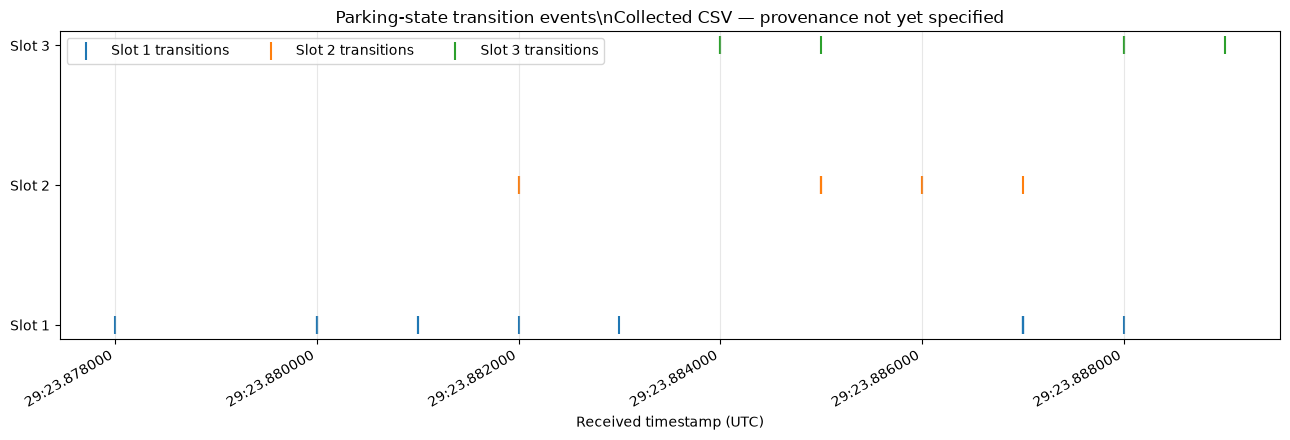

In [19]:
fig, ax = plt.subplots(figsize=(13, 4.5))
state_code = {"VACANT": 0, "OCCUPIED": 1, "UNKNOWN": 2}
for slot in range(1, 4):
    codes = df[f"slot{slot}_status"].map(state_code).to_numpy(dtype=float)
    changed = np.r_[False, codes[1:] != codes[:-1]]
    ax.scatter(
        df.loc[changed, "received_at_utc"],
        np.full(int(changed.sum()), slot),
        marker="|", s=180, label=f"Slot {slot} transitions"
    )
ax.set_yticks([1, 2, 3], labels=["Slot 1", "Slot 2", "Slot 3"])
ax.set_xlabel("Received timestamp (UTC)")
ax.set_title(f"Parking-state transition events\\n{DATA_SOURCE_LABEL}")
ax.grid(axis="x", alpha=0.3)
ax.legend(ncol=3)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(REPORT_DIR / "state_transition_timeline.png", dpi=180, bbox_inches="tight")
plt.show()

### 14.8 IQR-based distance outlier inspection

The interquartile-range (IQR) rule flags values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR. These are candidate outliers for inspection, not automatically erroneous measurements. Only valid non-negative readings are considered.

,Slot,Valid readings,Lower IQR bound (cm),Upper IQR bound (cm),Potential outliers,Potential outliers (%)
0,Slot 1,115,-158.300,288.260,0,0.0
1,Slot 2,102,-93.080,236.760,0,0.0
2,Slot 3,123,-154.705,293.655,0,0.0


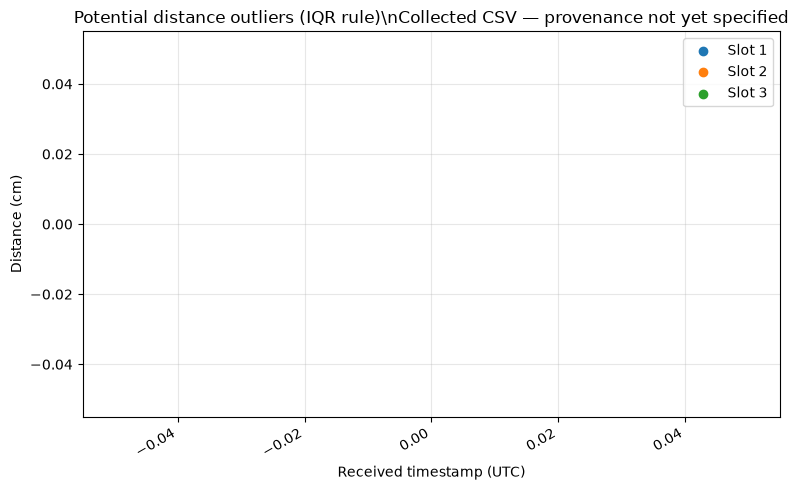

In [20]:
outlier_rows = []
for slot in range(1, 4):
    col = f"slot{slot}_distance_cm"
    values = pd.to_numeric(df[col], errors="coerce")
    valid = values[values >= 0].dropna()
    if len(valid) >= 4:
        q1, q3 = valid.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        mask = values.notna() & (values >= 0) & ((values < lower) | (values > upper))
        outlier_rows.append({
            "Slot": f"Slot {slot}", "Valid readings": len(valid),
            "Lower IQR bound (cm)": lower, "Upper IQR bound (cm)": upper,
            "Potential outliers": int(mask.sum()),
            "Potential outliers (%)": float(mask.sum() / len(valid) * 100)
        })
    else:
        outlier_rows.append({
            "Slot": f"Slot {slot}", "Valid readings": len(valid),
            "Lower IQR bound (cm)": np.nan, "Upper IQR bound (cm)": np.nan,
            "Potential outliers": np.nan, "Potential outliers (%)": np.nan
        })
outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary.round(3))
outlier_summary.to_csv(REPORT_DIR / "distance_iqr_outlier_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 5))
for slot in range(1, 4):
    col = f"slot{slot}_distance_cm"
    values = pd.to_numeric(df[col], errors="coerce")
    valid = values[values >= 0].dropna()
    if len(valid) >= 4:
        q1, q3 = valid.quantile([0.25, 0.75])
        iqr = q3 - q1
        mask = values.notna() & (values >= 0) & ((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr))
        ax.scatter(df.loc[mask, "received_at_utc"], values.loc[mask], label=f"Slot {slot}")
ax.set_title(f"Potential distance outliers (IQR rule)\\n{DATA_SOURCE_LABEL}")
ax.set_xlabel("Received timestamp (UTC)")
ax.set_ylabel("Distance (cm)")
ax.grid(True, alpha=0.3)
if ax.collections:
    ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(REPORT_DIR / "distance_iqr_outliers.png", dpi=180, bbox_inches="tight")
plt.show()

### 14.9 State transition matrices

A transition matrix counts consecutive state pairs for each slot. Rows represent the previous state and columns the next state. `UNKNOWN` remains a separate state.

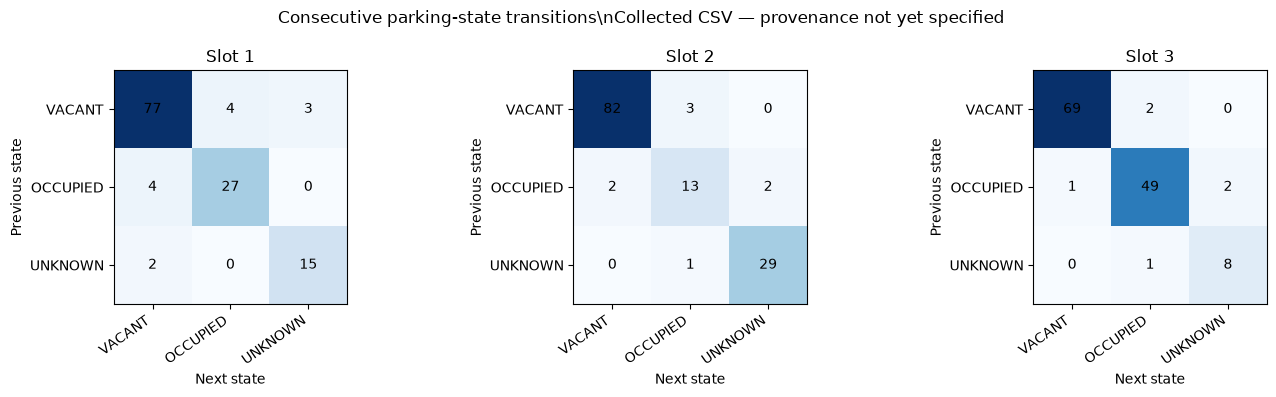

In [21]:
state_order = ["VACANT", "OCCUPIED", "UNKNOWN"]
transition_tables = {}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for slot, ax in enumerate(axes, start=1):
    states = df[f"slot{slot}_status"].astype(str)
    pairs = pd.DataFrame({"from": states.shift(1), "to": states})
    matrix = pd.crosstab(pairs["from"], pairs["to"]).reindex(
        index=state_order, columns=state_order, fill_value=0
    )
    transition_tables[f"Slot {slot}"] = matrix
    ax.imshow(matrix.to_numpy(), cmap="Blues")
    ax.set_xticks(range(3), labels=state_order, rotation=35, ha="right")
    ax.set_yticks(range(3), labels=state_order)
    ax.set_title(f"Slot {slot}")
    ax.set_xlabel("Next state")
    ax.set_ylabel("Previous state")
    for r in range(3):
        for c in range(3):
            ax.text(c, r, str(int(matrix.iloc[r, c])), ha="center", va="center")
    matrix.to_csv(REPORT_DIR / f"slot{slot}_transition_matrix.csv")
fig.suptitle(f"Consecutive parking-state transitions\\n{DATA_SOURCE_LABEL}")
fig.tight_layout()
fig.savefig(REPORT_DIR / "state_transition_matrices.png", dpi=180, bbox_inches="tight")
plt.show()

### 14.10 Interactive distance dashboard (optional Plotly)

If Plotly is installed, the chart below provides hover details and a legend for toggling sensors. The static Matplotlib plots above remain available without Plotly.

In [22]:
try:
    import plotly.graph_objects as go

    interactive_fig = go.Figure()
    for slot in range(1, 4):
        col = f"slot{slot}_distance_cm"
        values = pd.to_numeric(df[col], errors="coerce").where(df[col] >= 0)
        interactive_fig.add_trace(go.Scatter(
            x=df["received_at_utc"], y=values, mode="lines+markers",
            name=f"Slot {slot}", connectgaps=False
        ))
    interactive_fig.add_hline(y=25, line_dash="dash", annotation_text="Occupied threshold: 25 cm")
    interactive_fig.add_hline(y=30, line_dash="dot", annotation_text="Vacant threshold: 30 cm")
    interactive_fig.update_layout(
        title=f"Interactive PING))) distance dashboard — {DATA_SOURCE_LABEL}",
        xaxis_title="Received timestamp (UTC)", yaxis_title="Distance (cm)",
        hovermode="x unified"
    )
    interactive_fig.show()
    try:
        interactive_fig.write_html(REPORT_DIR / "interactive_distance_dashboard.html")
        print("Interactive dashboard saved.")
    except Exception as export_error:
        print(f"Interactive chart displayed, but HTML export failed: {export_error}")
except ImportError:
    print("Plotly is not installed. Install it with: python -m pip install plotly")

Interactive dashboard saved.


### 14.11 Normalized slot-performance radar chart

This chart compares three descriptive indicators: occupied share among known readings, valid distance-reading availability, and one minus the unknown-reading share. Each indicator is normalized across the three slots for visual comparison; it is not a validated composite performance score.

,Occupied share among known (%),Valid distance readings (%),Known status share (%)
Slot,,,
Slot 1,26.96,86.47,86.47
Slot 2,16.67,76.69,76.69
Slot 3,42.28,92.48,92.48


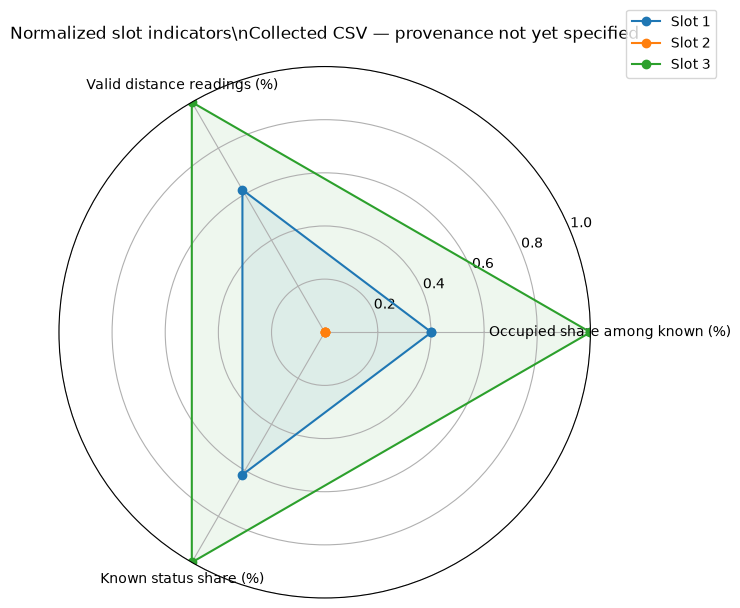

In [23]:
radar_metrics = pd.DataFrame({
    "Occupied share among known (%)": slot_summary["Occupied among known (%)"].to_numpy(),
    "Valid distance readings (%)": [
        pd.to_numeric(df[f"slot{slot}_distance_cm"], errors="coerce").ge(0).mean() * 100
        for slot in range(1, 4)
    ],
    "Known status share (%)": 100 - slot_summary["Unknown (%)"].to_numpy()
}, index=slot_summary["Slot"])

# Min-max normalization is used only for the radar display.
radar_norm = radar_metrics.copy()
for col in radar_norm.columns:
    low, high = radar_norm[col].min(), radar_norm[col].max()
    radar_norm[col] = ((radar_norm[col] - low) / (high - low)) if high > low else 0.5

display(radar_metrics.round(2))
angles = np.linspace(0, 2 * np.pi, len(radar_norm.columns), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"polar": True})
for slot_name, row in radar_norm.iterrows():
    values = row.to_list()
    values += values[:1]
    ax.plot(angles, values, marker="o", label=slot_name)
    ax.fill(angles, values, alpha=0.08)
ax.set_xticks(angles[:-1], labels=radar_norm.columns)
ax.set_ylim(0, 1)
ax.set_title(f"Normalized slot indicators\\n{DATA_SOURCE_LABEL}", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.12))
fig.tight_layout()
fig.savefig(REPORT_DIR / "normalized_slot_radar.png", dpi=180, bbox_inches="tight")
plt.show()

radar_metrics.to_csv(REPORT_DIR / "slot_indicator_comparison.csv")

## 15. Additional interpretation prompts

Use these supplementary plots to support, not replace, the evidence-based discussion:

1. Does the overall state composition indicate a balanced set of occupied and vacant observations, or is the dataset dominated by one state?
2. Do the distance histograms and violin plots show comparable distributions across the three sensors?
3. Are distance trends stable during the observation window, or do they drift?
4. Do sensor distances appear correlated? What physical explanation might account for the pattern?
5. Which state transitions occur most often, and are there repeated changes that warrant checking the sensor threshold or hysteresis behavior?
6. Are any IQR-flagged readings physically implausible, or could they represent genuine changes in target distance?
7. What limitations arise from the sample size, synthetic-vs-collected provenance, sensor placement and simulated environment?

Do not interpret correlation, IQR flags or the normalized radar chart as proof of sensor accuracy. Report the collection method and distinguish measured observations from derived indicators.